# 04a Regression race: set A

We predict log consumption (`LOGCONSUMPTION`) for every household. Then we rank the households in each village: the households with the lowest predicted consumption get the transfer.

This notebook uses feature set A: the variables of the government formula.

Models: OLS, Ridge, Lasso, Elastic Net, boosting regressor.
- Tuning score: CV MSE (lower = better predictions), on the saved village folds.
- Race metric: recall at the quota (out of all poor households, how many get the transfer).

### 1. Setup and loading

In [1]:
import sys
import os                    
sys.path.append("..")           

import numpy as np               
import pandas as pd              
import matplotlib.pyplot as plt  

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet   # regression models
from sklearn.ensemble import HistGradientBoostingRegressor  # boosting (class "Bagged Trees and Random Forests")
from sklearn.model_selection import cross_val_score, PredefinedSplit, RandomizedSearchCV   # cross-validation with our saved folds
from sklearn.pipeline import Pipeline   # preprocessing + model in one object
from sklearn.metrics import roc_auc_score   # ranking quality (class "Classification Metrics")

from src.utils import SEED, load_data, select_by_quota, recall_at_quota, within_village_auc   # shared group code
from src.features import SET_A, without_village_level, make_preprocessor  # shared feature lists + preprocessing
from src.features import skewed, other_numeric, binary    # which column gets which treatment

print("===== 04a Regression race: set A =====")   # header, so the output of main_notebooks shows where this notebook starts
print("SEED:", SEED)   # check that the shared seed is loaded (should be 40)

train, test = load_data()   # training villages (with their fold) and test villages, made in 01_data_prep
os.makedirs("../outputs/figures", exist_ok=True)   # folder for the figures of the report


===== 04a Regression race: set A =====
SEED: 40


### 2. Features (X) and target (y)

In [2]:
# Features: set A without the village-level columns
features = without_village_level(SET_A)   # 50 government-formula variables + 3 missing-value indicators
target = "LOGCONSUMPTION"                 # what we predict

print("number of features:", len(features)) 
print(features)

number of features: 53
['pcfloor', 'tfloor', 'twall', 'troof', 'toilet', 'water', 'lighting', 'fcook', 'house', 'hhsize', 'hhsize2', 'age04', 'eschild', 'jschild', 'sschild', 'depratio', 'hhage', 'hhage2', 'hhmale', 'hhmarried', 'hhmalemarr', 'hheduc2', 'hheduc3', 'hheduc4', 'hhsector1', 'hhsector2', 'hhsector3', 'formal', 'informal', 'higheduc2', 'higheduc3', 'higheduc4', 'credit', 'se2_17', 'se2_11_12', 'se2_125', 'se2_126_127', 'se2_119', 'se2_117', 'se2_115', 'se2_13_15', 'se2_14', 'se2_114', 'se2_18', 'se2_124', 'se2_122_123', 'se5_110', 'se5_11_12', 'se5_15_16', 'se2_138', 'hheduc_missing', 'no_workingage', 'pcfloor_missing']


We leave out the village-level columns (urban, district and village facilities) because they are the same for every household in a village. In a linear model, such a column adds the same amount to every household in the village, so the order inside the village stays the same.

In [3]:
# Train and test villages
print("train:", train.shape, "| villages:", train["hhea"].nunique())   # rows, columns, villages
print("test: ", test.shape, "| villages:", test["hhea"].nunique())
print("no village in both:", set(train["hhea"]).isdisjoint(test["hhea"]))   # must be True

train: (4090, 113) | villages: 512
test:  (1023, 112) | villages: 128
no village in both: True


We split by village because the model will be used in new villages. Households in one village share prices, roads and jobs. If neighbours were in both train and test, the test score would look too good. So we use the 128 test villages from 01_data_prep, and no village is in both parts.

In [4]:
# Features (X) and target (y) for training 
X_train = train[features].astype(float)   # features as decimal numbers (<NA> becomes NaN, filled later in the pipeline)
y_train = train[target]     # target for training

print("X_train:", X_train.shape, "| y_train:", y_train.shape)   # rows, columns

na = X_train.isna().sum()     # missing values per column (train)
print(na[na > 0])        # only columns with missing values
print("households with a missing value:", X_train.isna().any(axis=1).mean().round(3))   # True/False per row, then the share

X_train: (4090, 53) | y_train: (4090,)
pcfloor         42
toilet           7
water            1
depratio       177
hhage            4
hhage2           4
se2_122_123      4
se5_110          1
dtype: int64
households with a missing value: 0.057


### 3. Missing values: fill with the training median 

The regression models cannot work with missing values. So we will fill every gap with the median of the training data, and the 0/1 columns with their most frequent value.
We do not want to just delete these households because we would lose about 6% of the training data. Also, in real life the government must rank every household, even if one answer is missing.
We take the median instead of the mean because some features are very skewed and the median shows the typical household.

In [5]:
# Which columns get which treatment in make_preprocessor (src/features.py)
print("skewed numbers (median fill, then Yeo-Johnson):", skewed(features))
print("other numbers (median fill):                    ", other_numeric(features))
print("0/1 columns (most frequent value):              ", len(binary(features)), "columns")

skewed numbers (median fill, then Yeo-Johnson): ['pcfloor', 'eschild', 'depratio']
other numbers (median fill):                     ['hhsize', 'hhsize2', 'age04', 'jschild', 'sschild', 'hhage', 'hhage2']
0/1 columns (most frequent value):               43 columns


### 4. Scaling

The features are measured in very different units: floor area in m2, age squared in thousands, assets as 0/1. Scaling puts them all on the same scale (mean 0, standard deviation 1). This is very important for Ridge and Lasso, as they punish large coefficients. A coefficient's size depends on the unit of its feature. Without scaling, a feature measured in small numbers would get a big coefficient and be punished more, only because of its unit. After scaling, the penalty is fair to every feature. For the OLS, scaling does not change the predictions. But it makes the coefficients comparable: each one shows the effect of one standard deviation more of that feature.

Before scaling, three very skewed columns (pcfloor, eschild, depratio) get a Yeo-Johnson transform. It makes them more symmetric, so a few huge values do not pull the line too much. Unlike scaling, this does change the OLS predictions.

In [6]:
# Preprocessing 
prep = make_preprocessor(features)   # median fill + Yeo-Johnson + scaling
X_train_prep = pd.DataFrame(prep.fit_transform(X_train),    # learned on the training data only
                            columns=prep.get_feature_names_out())    # column names after preprocessing

cols = ["pcfloor", "hhsize", "hhage2", "toilet"]                  
print("train before preprocessing:")
display(X_train[cols].agg(["mean", "std"]).round(2))               
print("train after preprocessing:")
display(X_train_prep[cols].agg(["mean", "std"]).round(2))          
print("missing values left:", X_train_prep.isna().sum().sum())     

train before preprocessing:


,pcfloor,hhsize,hhage2,toilet
mean,24.60,4.35,2499.37,0.65
std,29.19,1.94,1484.73,0.48


train after preprocessing:


,pcfloor,hhsize,hhage2,toilet
mean,-0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0


missing values left: 0


**Result:**
- Before preprocessing, the features have very different sizes: `hhage2` has a mean of about 2,500, `pcfloor` about 25, `toilet` about 0.65.
- After preprocessing, every training feature has mean 0 and standard deviation 1, and no missing values are left.

### 5. OLS (linear regression without penalty)

In [7]:
# Cross-validation folds: the saved village folds from 01_data_prep
cv = PredefinedSplit(train["fold"])  

print("number of folds:", cv.get_n_splits())   
for k, (train_idx, val_idx) in enumerate(cv.split()):  # check each round
    print(f"round {k}: train {len(train_idx)} | validation {len(val_idx)}")

number of folds: 5
round 0: train 3268 | validation 822
round 1: train 3268 | validation 822
round 2: train 3275 | validation 815
round 3: train 3275 | validation 815
round 4: train 3274 | validation 816


In [8]:
# Cross-validation error of OLS
ols = Pipeline([
    ("prep", make_preprocessor(features, drop_first=True)),   # fill + Yeo-Johnson + scale (drop_first only matters for district dummies, and there are none here)
    ("model", LinearRegression()),   # OLS model, no penalty
])
cv_score = cross_val_score(ols, X_train, y_train, cv=cv,
                           scoring="neg_mean_squared_error")  # preprocessing is learned again in every round
ols_cv_mse = -np.mean(cv_score)      # flip the sign, average over the 5 folds

print("MSE per fold:", (-cv_score).round(4))  # error in each validation fold
print(f"OLS CV MSE:  {ols_cv_mse:.4f}")                       
print(f"OLS CV RMSE: {np.sqrt(ols_cv_mse):.4f}")               
print(f"MSE if we always guess the mean: {y_train.var():.4f}")
print(f"R2 = 1 - MSE / variance: {1 - ols_cv_mse / y_train.var():.2f}")  # share of the variation that OLS explains

MSE per fold: [0.2373 0.2106 0.2573 0.2453 0.2204]
OLS CV MSE:  0.2341
OLS CV RMSE: 0.4839
MSE if we always guess the mean: 0.4549
R2 = 1 - MSE / variance: 0.49


In [9]:
# Fit OLS on all training households and look at the coefficients
ols.fit(X_train, y_train)      # preprocessing + OLS, learned on all training data
names = ols.named_steps["prep"].get_feature_names_out()    # column names after preprocessing
ols_coefs = pd.Series(ols.named_steps["model"].coef_, index=names)   # coefficients with the right names

print(f"intercept: {ols.named_steps['model'].intercept_:.3f}")  # prediction for an average household
print(f"mean of y_train: {y_train.mean():.3f}")               
top = ols_coefs.abs().sort_values(ascending=False).index[:10]   # names of the 10 largest coefficients (by size)
display(ols_coefs.loc[top].round(3))                            

intercept: 6.062
mean of y_train: 6.062


hhsize        -0.571
hhsize2        0.346
pcfloor        0.079
se2_117        0.072
fcook          0.069
se2_125        0.067
se2_126_127    0.067
se2_119        0.061
hhage2        -0.058
se2_18         0.053
dtype: float64

**Result:**

OLS has a CV MSE of 0.234. If we always guess the mean, the MSE is 0.455. So R² ≈ 0.49: the features explain about half of the differences in log consumption between households.

The intercept (6.062) is the same as the mean of y_train, because all features are scaled to mean 0. So it is the prediction for an average household.

The largest coefficient is hhsize (-0.57): bigger households have lower consumption per person. hhsize2 is positive (0.35), so this effect gets weaker for very big households. More floor area per person (pcfloor), the cooking fuel (fcook) and several assets go with higher consumption. Because the features are scaled, each coefficient is the effect of one standard deviation more of that feature.

### 6. Ridge and Lasso

Ridge and Lasso are OLS plus a penalty for large coefficients. The alpha sets how strong the penalty is.
- Ridge punishes the squared coefficients. It makes all of them smaller, but none becomes exactly 0. This helps when features carry similar information (e.g. `hhage` and `hhage2`, or `hhmale` and `hhmalemarr`). OLS can then give them large opposite weights, and Ridge calms this down.
- Lasso punishes the absolute size of the coefficients. It can set some of them exactly to 0, so it also chooses features.
- alpha = 0 is plain OLS. A very large alpha pushes all coefficients to 0, and the model only predicts the mean.

In [10]:
# Penalty strengths to try
alphas_ridge = np.logspace(-3, 3, 20)   # Ridge: 20 values from 0.001 to 1000, evenly spread on a log scale
alphas_lasso = np.logspace(-4, 0, 20)   # Lasso: 20 values from 0.0001 to 1

print(f"Ridge: {len(alphas_ridge)} values from {alphas_ridge.min()} to {alphas_ridge.max()}")
print(f"Lasso: {len(alphas_lasso)} values from {alphas_lasso.min()} to {alphas_lasso.max()}")

Ridge: 20 values from 0.001 to 1000.0
Lasso: 20 values from 0.0001 to 1.0


#### Ridge
For each alpha, we compute the CV error with the same 5 village folds. Then we pick the alpha with the lowest error.

In [11]:
# Ridge: CV error for every alpha
ridge_scores = []      # CV MSE for each alpha
for alpha in alphas_ridge:    # try each alpha
    ridge_model = Pipeline([
        ("prep", make_preprocessor(features)),              
        ("model", Ridge(alpha=alpha)),   # Ridge with this penalty
    ])
    cv_score = cross_val_score(ridge_model, X_train, y_train, cv=cv,
                               scoring="neg_mean_squared_error")  
    ridge_scores.append(-np.mean(cv_score))    # flip the sign, save the average MSE

best_alpha_ridge = alphas_ridge[np.argmin(ridge_scores)]     # alpha with the lowest CV error
best_score_ridge = np.min(ridge_scores)   

print(f"Best alpha: {best_alpha_ridge:.3f}")
print(f"Ridge CV MSE: {best_score_ridge:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best alpha: 6.158
Ridge CV MSE: 0.23411 | OLS CV MSE: 0.23415


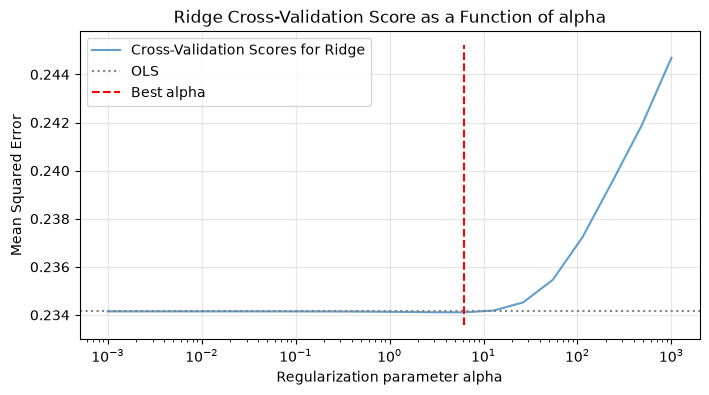

In [12]:
# Plot: Ridge CV error for each alpha
fig, ax = plt.subplots(figsize=(8, 4))

# CV error for each alpha that was tried
ax.plot(alphas_ridge, ridge_scores,alpha=0.7, label="Cross-Validation Scores for Ridge")
# OLS for comparison
ax.axhline(ols_cv_mse, color="grey", linestyle=":", label="OLS")
# The chosen alpha
ax.vlines(best_alpha_ridge, ax.get_ylim()[0], ax.get_ylim()[1], linestyle="--", color="red", label="Best alpha")

# Aesthetics
ax.set_xscale("log")  # alphas are spread on a log scale
ax.set_xlabel("Regularization parameter alpha")
ax.set_ylabel("Mean Squared Error")
ax.set_title("Ridge Cross-Validation Score as a Function of alpha")
ax.grid(alpha=0.3)
ax.legend()
fig.savefig("../outputs/figures/04a_regression_setA_figure1.png", dpi=200, bbox_inches="tight")   # saved for the report
plt.show()

In [13]:
# Fit Ridge with the best alpha on all training households
ridge = Pipeline([
    ("prep", make_preprocessor(features)),                  
    ("model", Ridge(alpha=best_alpha_ridge)),   # Ridge with the chosen penalty
])
ridge.fit(X_train, y_train)                                 
ridge_coefs = pd.Series(ridge.named_steps["model"].coef_,
                        index=ridge.named_steps["prep"].get_feature_names_out())   

compare = pd.DataFrame({"OLS": ols_coefs, "Ridge": ridge_coefs})   # side by side (matched by name)
display(compare.loc[top].round(3))   # same 10 features as in the OLS table

,OLS,Ridge
hhsize,-0.571,-0.543
hhsize2,0.346,0.323
pcfloor,0.079,0.081
se2_117,0.072,0.072
fcook,0.069,0.069
se2_125,0.067,0.067
se2_126_127,0.067,0.067
se2_119,0.061,0.061
hhage2,-0.058,-0.046
se2_18,0.053,0.052


#### Lasso

In [14]:
# Lasso: CV error for every alpha
lasso_scores = []      
for alpha in alphas_lasso:    
    lasso_model = Pipeline([
        ("prep", make_preprocessor(features)),              
        ("model", Lasso(alpha=alpha, max_iter=10000)),      
    ])
    cv_score = cross_val_score(lasso_model, X_train, y_train, cv=cv,
                               scoring="neg_mean_squared_error")   # same village folds as OLS and Ridge
    lasso_scores.append(-np.mean(cv_score))                  

best_alpha_lasso = alphas_lasso[np.argmin(lasso_scores)]     # alpha with the lowest CV error
best_score_lasso = np.min(lasso_scores)                     

print(f"Best alpha: {best_alpha_lasso:.4f}")
print(f"Lasso CV MSE: {best_score_lasso:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best alpha: 0.0007
Lasso CV MSE: 0.23406 | OLS CV MSE: 0.23415


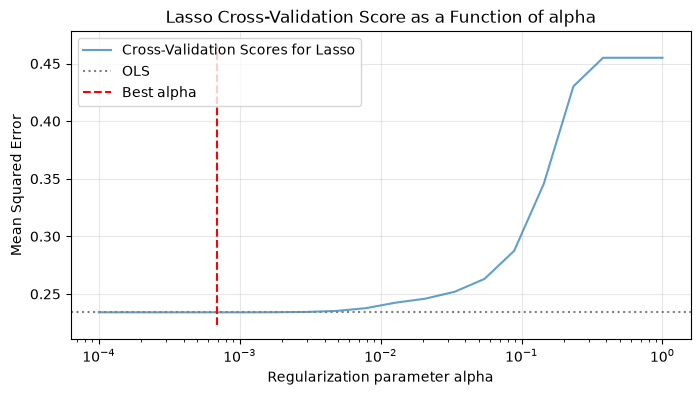

In [15]:
# Plot: Lasso CV error for each alpha
fig, ax = plt.subplots(figsize=(8, 4))

# CV error for each alpha that was tried
ax.plot(alphas_lasso, lasso_scores,
        alpha=0.7, label="Cross-Validation Scores for Lasso")
# OLS for comparison
ax.axhline(ols_cv_mse, color="grey", linestyle=":", label="OLS")
# The chosen alpha
ax.vlines(best_alpha_lasso, ax.get_ylim()[0], ax.get_ylim()[1], linestyle="--", color="red", label="Best alpha")

# Aesthetics
ax.set_xscale("log")        
ax.set_xlabel("Regularization parameter alpha")
ax.set_ylabel("Mean Squared Error")
ax.set_title("Lasso Cross-Validation Score as a Function of alpha")
ax.grid(alpha=0.3)
ax.legend()
fig.savefig("../outputs/figures/04a_regression_setA_figure2.png", dpi=200, bbox_inches="tight")   # saved for the report
plt.show()

In [16]:
# Fit Lasso with the best alpha on all training households. Which features did it drop?
lasso = Pipeline([
    ("prep", make_preprocessor(features)),                      
    ("model", Lasso(alpha=best_alpha_lasso, max_iter=10000)), # Lasso with the chosen penalty
])
lasso.fit(X_train, y_train)                                      
lasso_coefs = pd.Series(lasso.named_steps["model"].coef_,
                        index=lasso.named_steps["prep"].get_feature_names_out())   
zero = lasso_coefs[lasso_coefs == 0].index.tolist()     # features with coefficient exactly 0

print(f"coefficients set to 0: {len(zero)} of {len(features)}")
print(zero)      # names of the dropped features
top_lasso = lasso_coefs.abs().sort_values(ascending=False).index[:10]   # 10 largest Lasso coefficients (by size)
display(lasso_coefs.loc[top_lasso].round(3))                           

coefficients set to 0: 3 of 53
['eschild', 'hhage', 'hhsector1']


hhsize        -0.537
hhsize2        0.318
pcfloor        0.081
se2_117        0.072
fcook          0.069
se2_125        0.067
se2_126_127    0.066
se2_119        0.062
se2_18         0.052
se2_115        0.048
dtype: float64

#### Comparison of OLS, Ridge and Lasso (cross-validation)

In [17]:
# Compare the CV errors of the three models
cv_results = pd.DataFrame({
    "Model":  ["OLS", "Ridge", "Lasso"],  
    "alpha":  [0, best_alpha_ridge, best_alpha_lasso],   # chosen penalty (OLS = no penalty)
    "CV MSE": [ols_cv_mse, best_score_ridge, best_score_lasso],  # average CV error
}).set_index("Model").sort_values("CV MSE")     # lowest error first
cv_results["CV RMSE"] = np.sqrt(cv_results["CV MSE"])      # error in log-consumption units

display(cv_results.round(5)) # 5 decimals                                     

,alpha,CV MSE,CV RMSE
Model,,,
Lasso,0.00070,0.23406,0.48380
Ridge,6.15848,0.23411,0.48385
OLS,0.00000,0.23415,0.48389


**Result:**

All three models have almost the same CV error. Lasso has 0.23406 (alpha 0.0007), Ridge 0.23411 (alpha 6.16) and OLS 0.23415. In log consumption, this is an RMSE of about 0.484 for all three.

The differences between the models are much smaller than the differences between the folds. For OLS, the error goes from 0.211 to 0.257 depending on the fold. The models differ by less than 0.0001. So the differences between OLS, Ridge and Lasso are only noise, and none of them is really better. 

The best alphas are small, so Ridge and Lasso stay very close to OLS. Lasso sets only 3 of 53 coefficients to 0 (eschild, hhage, hhsector1). Their information is mostly also in other features, like hhsize, age04 and hhage2.

The penalty does not help because we have 4,090 training households and only 53 features, about 77 households per feature. With so much data, OLS does not overfit, so the penalty has nothing to fix. Also, the features come from the government formula, so they were already chosen to be useful.

With the MSE, the three models are tied, so we cannot choose between them yet.


### 7. CV recall at the quota (the race metric)

The MSE shows how close the predicted consumption is. But the government does not need exact numbers. It needs to choose the right households. In every village, the round (village size × share) households with the lowest predicted consumption get the transfer. The share is the village's quota: the part of its households that can get a transfer. Recall at the quota = out of all poor households, how many get the transfer. A household counts as poor (column `poor`) if its consumption is below the local poverty line. This is the main metric of our project, and the race is decided on it.
- We compute it in the 5 validation folds: fit on 4 folds, predict the 5th, choose the households village by village, and compare with `poor`.
- We also report precision, accuracy, ROC AUC and the within-village AUC. The within-village AUC only compares a poor and a non-poor household from the same village, because the quota also ranks inside each village.
- As references, with the same folds and quota: the government formula (pcexppred), a random ranking (the floor) and a ranking by true consumption (the ceiling).


In [18]:
# Targeting metrics for one validation fold
def targeting_metrics(val, score, name, k):
    selected = select_by_quota(val, score, higher_is_poorer=False)   # lowest predicted consumption gets the transfer
    poor = val["poor"].astype(int)   # true label: 1 = poor
    return {
        "model": name,
        "fold": k,
        "recall": recall_at_quota(val, selected),  # poor selected / all poor (main metric)
        "precision": poor[selected == 1].mean(),   # share of poor among the selected households
        "accuracy": (selected == poor).mean(),   # correct decisions / all households
        "roc_auc": roc_auc_score(poor, -val[score]),  # ranking quality over all households; minus, because low consumption = poor
        "within_auc": within_village_auc(val, score, higher_is_poorer=False),  # only pairs in the same village
    }

In [19]:
# The three models with their chosen alpha
models = {
    "OLS":   Pipeline([("prep", make_preprocessor(features, drop_first=True)), ("model", LinearRegression())]),
    "Ridge": Pipeline([("prep", make_preprocessor(features)), ("model", Ridge(alpha=best_alpha_ridge))]),
    "Lasso": Pipeline([("prep", make_preprocessor(features)), ("model", Lasso(alpha=best_alpha_lasso, max_iter=10000))]),
}
metrics = ["recall", "precision", "accuracy", "roc_auc", "within_auc"]  
references = ["Government formula", "Random", "Perfect ranking"]        
rng = np.random.default_rng(SEED)                                       

rows = []    # one row per model and fold
for k, (train_idx, val_idx) in enumerate(cv.split()):  # same 5 village folds as before
    val = train.iloc[val_idx].copy()    # the validation villages (whole villages)
    for name, model in models.items():
        model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])   # learn on the other 4 folds (preprocessing too)
        val[name] = model.predict(X_train.iloc[val_idx])   # predicted log consumption in fold k
        rows.append(targeting_metrics(val, name, name, k))
    rows.append(targeting_metrics(val, "pcexppred", "Government formula", k))   # reference: the government's formula
    rows.append(targeting_metrics(val, "LOGCONSUMPTION", "Perfect ranking", k))   # ceiling: ranking by the true consumption

    random_runs = []   # floor: 100 random rankings, then the average
    for r in range(100):
        val["Random"] = rng.random(len(val))  # a random score for every household
        random_runs.append(targeting_metrics(val, "Random", "Random", k))
    random_row = pd.DataFrame(random_runs)[metrics].mean().to_dict()   # average over the 100 random rankings
    random_row["model"] = "Random"
    random_row["fold"] = k
    rows.append(random_row)

fold_results = pd.DataFrame(rows)                                  

In [20]:
# Recall in every fold
display(fold_results.pivot(index="fold", columns="model", values="recall").round(3))

# Mean and standard deviation across the 5 folds, best recall first
summary = fold_results.groupby("model")[metrics].agg(["mean", "std"])
summary = summary.sort_values(("recall", "mean"), ascending=False)   # sort by mean recall
display(summary.round(3))

model,Government formula,Lasso,OLS,Perfect ranking,Random,Ridge
fold,,,,,,
0,0.559,0.592,0.589,0.716,0.367,0.592
1,0.544,0.582,0.582,0.682,0.374,0.582
2,0.548,0.551,0.545,0.664,0.352,0.545
3,0.552,0.569,0.573,0.729,0.383,0.569
4,0.498,0.516,0.516,0.639,0.341,0.516


recall        precision        accuracy        roc_auc  \
                     mean    std      mean    std     mean    std    mean   
model                                                                       
Perfect ranking     0.686  0.037     0.769  0.033    0.811  0.013   0.993   
Lasso               0.562  0.030     0.631  0.045    0.722  0.017   0.822   
OLS                 0.561  0.030     0.629  0.043    0.721  0.016   0.822   
Ridge               0.561  0.031     0.629  0.045    0.721  0.017   0.823   
Government formula  0.540  0.024     0.606  0.038    0.706  0.013   0.795   
Random              0.364  0.017     0.408  0.020    0.578  0.012   0.501   

                          within_auc         
                      std       mean    std  
model                                        
Perfect ranking     0.002      1.000  0.000  
Lasso               0.022      0.825  0.025  
OLS                 0.021      0.824  0.025  
Ridge               0.021      0.825  0.025  
Government formula  0.026      0.777  0.023  
Random              0.001      0.500  0.002

**Result:**

OLS, Ridge and Lasso all reach about 56% recall at the quota. This means that out of 100 poor households, they find about 56. The government formula finds about 54, a random ranking about 36, and a perfect ranking about 69. Even the perfect ranking cannot reach 100%, because in poorer villages there are more poor households than transfers.

The recall of all models goes up and down together from fold to fold, because some villages are harder than others. So we compare the models fold by fold, on the same villages. OLS and Ridge beat the government formula in 4 of the 5 folds, and Lasso in all 5. Their ranking within the villages is also clearly better (within-village AUC 0.82 vs. 0.78).

The gain is small, about 2 points, but fairly consistent. We check it again in section 10.

### 8. Elastic net 

In [21]:
# Elastic net
alphas_enet = np.logspace(-4, 0, 15)   
l1_ratios = [0.1, 0.5, 0.9]       # mix of the two penalties: 1 = only Lasso, 0 = only Ridge

enet_scores = {}    # for each l1_ratio: a list with the CV MSE of every alpha
for l1 in l1_ratios:   # try each mix
    enet_scores[l1] = []
    for alpha in alphas_enet: # try each alpha
        enet_model = Pipeline([
            ("prep", make_preprocessor(features)),
            ("model", ElasticNet(alpha=alpha, l1_ratio=l1, max_iter=10000)),
        ])
        cv_score = cross_val_score(enet_model, X_train, y_train, cv=cv,
                                   scoring="neg_mean_squared_error")  
        enet_scores[l1].append(-np.mean(cv_score))                   

enet_table = pd.DataFrame(enet_scores, index=alphas_enet)   # rows: alpha, columns: l1_ratio
best_l1_enet = enet_table.min().idxmin()   # l1_ratio with the lowest CV error
best_alpha_enet = enet_table[best_l1_enet].idxmin()   # the best alpha for that l1_ratio
best_score_enet = enet_table.min().min()    # that lowest CV error

print(f"Best l1_ratio: {best_l1_enet} | best alpha: {best_alpha_enet:.4f}")
print(f"Elastic Net CV MSE: {best_score_enet:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best l1_ratio: 0.9 | best alpha: 0.0007
Elastic Net CV MSE: 0.23406 | OLS CV MSE: 0.23415


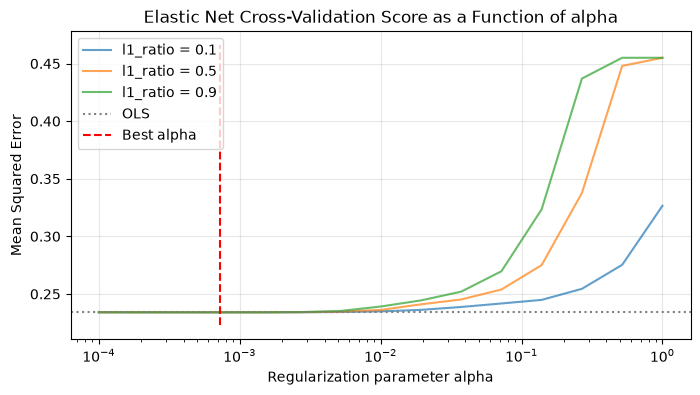

In [22]:
# Plot: Elastic Net CV error for each alpha
fig, ax = plt.subplots(figsize=(8, 4))

# CV error for each alpha, one line for each mix of the penalties
for l1 in l1_ratios:
    ax.plot(alphas_enet, enet_table[l1], alpha=0.7, label=f"l1_ratio = {l1}")
# OLS for comparison
ax.axhline(ols_cv_mse, color="grey", linestyle=":", label="OLS")
# The chosen alpha
ax.vlines(best_alpha_enet, ax.get_ylim()[0], ax.get_ylim()[1], linestyle="--", color="red", label="Best alpha")

# Aesthetics
ax.set_xscale("log")  
ax.set_xlabel("Regularization parameter alpha")
ax.set_ylabel("Mean Squared Error")
ax.set_title("Elastic Net Cross-Validation Score as a Function of alpha")
ax.grid(alpha=0.3)
ax.legend()
fig.savefig("../outputs/figures/04a_regression_setA_figure3.png", dpi=200, bbox_inches="tight")   # saved for the report
plt.show()

In [23]:
# Fit Elastic Net with the best alpha and l1_ratio on all training households
enet = Pipeline([
    ("prep", make_preprocessor(features)),
    ("model", ElasticNet(alpha=best_alpha_enet, l1_ratio=best_l1_enet, max_iter=10000)),
])
enet.fit(X_train, y_train)                                      
enet_coefs = pd.Series(enet.named_steps["model"].coef_,
                       index=enet.named_steps["prep"].get_feature_names_out())   
zero_enet = enet_coefs[enet_coefs == 0].index.tolist()    # features with coefficient exactly 0

print(f"coefficients set to 0: {len(zero_enet)} of {len(features)}")
print(zero_enet)     # names of the dropped features

compare_enet = pd.DataFrame({"OLS": ols_coefs, "Lasso": lasso_coefs, "Elastic Net": enet_coefs})   
display(compare_enet.loc[top].round(3))                      

coefficients set to 0: 3 of 53
['eschild', 'hhage', 'hhsector1']


,OLS,Lasso,Elastic Net
hhsize,-0.571,-0.537,-0.538
hhsize2,0.346,0.318,0.319
pcfloor,0.079,0.081,0.081
se2_117,0.072,0.072,0.072
fcook,0.069,0.069,0.069
se2_125,0.067,0.067,0.067
se2_126_127,0.067,0.066,0.066
se2_119,0.061,0.062,0.061
hhage2,-0.058,-0.019,-0.019
se2_18,0.053,0.052,0.052


In [24]:
# Recall at the quota for Elastic Net
enet_rows = []                                                    
for k, (train_idx, val_idx) in enumerate(cv.split()):            
    val = train.iloc[val_idx].copy()                            
    enet_fold = Pipeline([
        ("prep", make_preprocessor(features)),
        ("model", ElasticNet(alpha=best_alpha_enet, l1_ratio=best_l1_enet, max_iter=10000)),
    ])
    enet_fold.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])   # learn on the other 4 folds
    val["Elastic Net"] = enet_fold.predict(X_train.iloc[val_idx])   # predicted log consumption in fold k
    enet_rows.append(targeting_metrics(val, "Elastic Net", "Elastic Net", k))

fold_results_all = pd.concat([fold_results, pd.DataFrame(enet_rows)], ignore_index=True)   

# Mean and standard deviation across the 5 folds
summary_all = fold_results_all.groupby("model")[metrics].agg(["mean", "std"])
summary_all = summary_all.sort_values(("recall", "mean"), ascending=False)
display(summary_all.round(3))

recall        precision        accuracy        roc_auc  \
                     mean    std      mean    std     mean    std    mean   
model                                                                       
Perfect ranking     0.686  0.037     0.769  0.033    0.811  0.013   0.993   
Lasso               0.562  0.030     0.631  0.045    0.722  0.017   0.822   
Elastic Net         0.562  0.029     0.630  0.044    0.721  0.016   0.822   
OLS                 0.561  0.030     0.629  0.043    0.721  0.016   0.822   
Ridge               0.561  0.031     0.629  0.045    0.721  0.017   0.823   
Government formula  0.540  0.024     0.606  0.038    0.706  0.013   0.795   
Random              0.364  0.017     0.408  0.020    0.578  0.012   0.501   

                          within_auc         
                      std       mean    std  
model                                        
Perfect ranking     0.002      1.000  0.000  
Lasso               0.022      0.825  0.025  
Elastic Net         0.022      0.825  0.025  
OLS                 0.021      0.824  0.025  
Ridge               0.021      0.825  0.025  
Government formula  0.026      0.777  0.023  
Random              0.001      0.500  0.002

**Result:**

The best Elastic Net is almost pure Lasso (l1_ratio 0.9, alpha 0.0007). It has the same error (MSE 0.234), drops the same 3 features, and has almost the same coefficients as Lasso.

On the plot, the more Lasso is in the mix, the earlier the error goes up, because more coefficients become 0.

Recall at the quota is 56.2%, the same as OLS, Ridge and Lasso. So mixing the penalties does not help either. With the simplicity rule (see section 10), we still prefer OLS.


### 9. Boosting regressor

Boosting uses set A with the village-level columns (district, urban, village facilities), because trees can combine them with household features. It needs no scaling, because a tree only asks if a value is above or below a cutoff.

Boosting has many settings, so we do not try every combination. RandomizedSearchCV tries 40 random combinations from the grid in our outline, on the same village folds, and keeps the one with the lowest CV MSE. We turn off the built-in early stopping, because it would hold out random households and ignore the villages. To check if the village-level columns matter, we also run the same boosting without them.

In [25]:
# Boosting, set A
features_boost = SET_A     # 62 formula variables + 3 indicators + district
X_train_boost = train[features_boost].copy()    # same training households, more columns
num_cols = [c for c in features_boost if c != "kabu"]  # all columns except the district code
X_train_boost[num_cols] = X_train_boost[num_cols].astype(float)  # decimal numbers 

boost = Pipeline([
    ("prep", make_preprocessor(features_boost, scale=False)),  # fill missing values + district one-hot, no scaling
    ("model", HistGradientBoostingRegressor(early_stopping=False, random_state=SEED)),   # no built-in early stopping
])


param_distributions = {
    "model__learning_rate": [0.02, 0.05, 0.1],    # how much each new tree corrects
    "model__max_iter": [100, 200, 400, 800],      # number of trees
    "model__max_depth": [2, 3, 4, 5],             # how deep each tree can grow
    "model__min_samples_leaf": [20, 50, 100],     # minimum households in a leaf (bigger = smoother)
    "model__l2_regularization": [0, 0.1, 1],      # penalty on the leaf values
}

search = RandomizedSearchCV(                          
    boost, param_distributions=param_distributions,
    n_iter=40,       # 40 random combinations
    scoring="neg_mean_squared_error",                  
    cv=cv,    
    random_state=SEED,                               
    return_train_score=True,    # keep the training error (to see overfitting)
    n_jobs=-1,  
)
search.fit(X_train_boost, y_train)   # tries all 40, then refits the best on all training households

best_params_boost = search.best_params_     # the best settings
best_score_boost = -search.best_score_      # their CV MSE (flip the sign)
print("Best settings:", best_params_boost)
print(f"Boosting CV MSE: {best_score_boost:.5f} | OLS CV MSE: {ols_cv_mse:.5f}")

Best settings: {'model__min_samples_leaf': 50, 'model__max_iter': 200, 'model__max_depth': 2, 'model__learning_rate': 0.1, 'model__l2_regularization': 1}
Boosting CV MSE: 0.22191 | OLS CV MSE: 0.23415


In [26]:
# The 5 best combinations
results_boost = pd.DataFrame(search.cv_results_)     # one row per combination that was tried
results_boost["CV MSE"] = -results_boost["mean_test_score"]  # flip the sign
results_boost["CV MSE std"] = results_boost["std_test_score"]    # spread across the 5 folds
results_boost["train MSE"] = -results_boost["mean_train_score"]  # error on the data the model learned from

show = ["param_model__learning_rate", "param_model__max_iter", "param_model__max_depth",
        "param_model__min_samples_leaf", "param_model__l2_regularization",
        "CV MSE", "CV MSE std", "train MSE"]
display(results_boost.sort_values("CV MSE")[show].head(5).round(4))

,param_model__learning_rate,param_model__max_iter,param_model__max_depth,param_model__min_samples_leaf,param_model__l2_regularization,CV MSE,CV MSE std,train MSE
8,0.10,200,2,50,1.0,0.2219,0.0132,0.1948
7,0.02,800,3,50,0.1,0.2229,0.0130,0.1788
19,0.05,800,2,100,0.1,0.2231,0.0137,0.1880
29,0.10,400,2,20,0.0,0.2233,0.0140,0.1773
2,0.02,800,2,20,0.0,0.2235,0.0153,0.1965


In [27]:
# Check: the same boosting (same settings), but WITHOUT the village-level columns
boost_nv = Pipeline([
    ("prep", make_preprocessor(features, scale=False)),    # the 53 columns of the linear models, no scaling
    ("model", HistGradientBoostingRegressor(early_stopping=False, random_state=SEED)),
])
boost_nv.set_params(**best_params_boost)   # same settings as the best boosting above
cv_score = cross_val_score(boost_nv, X_train, y_train, cv=cv,
                           scoring="neg_mean_squared_error") 
best_score_boost_nv = -np.mean(cv_score)      

print(f"Boosting with village columns:    CV MSE {best_score_boost:.5f}")
print(f"Boosting without village columns: CV MSE {best_score_boost_nv:.5f}")
print(f"OLS (no village columns):         CV MSE {ols_cv_mse:.5f}")

Boosting with village columns:    CV MSE 0.22191
Boosting without village columns: CV MSE 0.23083
OLS (no village columns):         CV MSE 0.23415


In [28]:
# Recall at the quota for boosting, with and without the village-level columns
boost_rows = []     # one row per model and fold
for k, (train_idx, val_idx) in enumerate(cv.split()):   
    val = train.iloc[val_idx].copy()    # the validation villages

    boost_fold = Pipeline([    # with the village-level columns
        ("prep", make_preprocessor(features_boost, scale=False)),
        ("model", HistGradientBoostingRegressor(early_stopping=False, random_state=SEED)),
    ])
    boost_fold.set_params(**best_params_boost)     # use the best settings from the search
    boost_fold.fit(X_train_boost.iloc[train_idx], y_train.iloc[train_idx])    # learn on the other 4 folds
    val["Boosting"] = boost_fold.predict(X_train_boost.iloc[val_idx])     # predicted log consumption in fold k
    boost_rows.append(targeting_metrics(val, "Boosting", "Boosting", k))

    boost_nv_fold = Pipeline([   # without the village-level columns
        ("prep", make_preprocessor(features, scale=False)),
        ("model", HistGradientBoostingRegressor(early_stopping=False, random_state=SEED)),
    ])
    boost_nv_fold.set_params(**best_params_boost)             
    boost_nv_fold.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    val["Boosting (no village)"] = boost_nv_fold.predict(X_train.iloc[val_idx])
    boost_rows.append(targeting_metrics(val, "Boosting (no village)", "Boosting (no village)", k))

fold_results_boost = pd.concat([fold_results_all, pd.DataFrame(boost_rows)], ignore_index=True)   # all models so far

# Recall in every fold
display(fold_results_boost.pivot(index="fold", columns="model", values="recall").round(3))

# Mean and sd
summary_boost = fold_results_boost.groupby("model")[metrics].agg(["mean", "std"])
summary_boost = summary_boost.sort_values(("recall", "mean"), ascending=False)
display(summary_boost.round(3))

candidates = summary_boost.drop(index=references)   # reference rows are not candidates
best_mean = candidates[("recall", "mean")].iloc[0]
best_std = candidates[("recall", "std")].iloc[0]
within = candidates.index[candidates[("recall", "mean")] >= best_mean - best_std].tolist()
print(f"best mean recall: {best_mean:.3f} (std {best_std:.3f})")
print("candidates within one std of the best:", within)

model,Boosting,Boosting (no village),Elastic Net,Government formula,Lasso,OLS,Perfect ranking,Random,Ridge
fold,,,,,,,,,
0,0.582,0.579,0.589,0.559,0.592,0.589,0.716,0.367,0.592
1,0.582,0.566,0.582,0.544,0.582,0.582,0.682,0.374,0.582
2,0.548,0.548,0.551,0.548,0.551,0.545,0.664,0.352,0.545
3,0.583,0.573,0.569,0.552,0.569,0.573,0.729,0.383,0.569
4,0.509,0.516,0.516,0.498,0.516,0.516,0.639,0.341,0.516


recall        precision        accuracy        roc_auc  \
                        mean    std      mean    std     mean    std    mean   
model                                                                          
Perfect ranking        0.686  0.037     0.769  0.033    0.811  0.013   0.993   
Lasso                  0.562  0.030     0.631  0.045    0.722  0.017   0.822   
Elastic Net            0.562  0.029     0.630  0.044    0.721  0.016   0.822   
OLS                    0.561  0.030     0.629  0.043    0.721  0.016   0.822   
Ridge                  0.561  0.031     0.629  0.045    0.721  0.017   0.823   
Boosting               0.561  0.033     0.629  0.041    0.721  0.012   0.835   
Boosting (no village)  0.556  0.025     0.624  0.036    0.718  0.011   0.824   
Government formula     0.540  0.024     0.606  0.038    0.706  0.013   0.795   
Random                 0.364  0.017     0.408  0.020    0.578  0.012   0.501   

                             within_auc         
                         std       mean    std  
model                                           
Perfect ranking        0.002      1.000  0.000  
Lasso                  0.022      0.825  0.025  
Elastic Net            0.022      0.825  0.025  
OLS                    0.021      0.824  0.025  
Ridge                  0.021      0.825  0.025  
Boosting               0.017      0.823  0.022  
Boosting (no village)  0.021      0.819  0.023  
Government formula     0.026      0.777  0.023  
Random                 0.001      0.500  0.002

best mean recall: 0.562 (std 0.030)
candidates within one std of the best: ['Lasso', 'Elastic Net', 'OLS', 'Ridge', 'Boosting', 'Boosting (no village)']


**Result:**

The best boosting model is simple: small trees (depth 2), 200 trees and a strong penalty. Its CV error is lower than for OLS (MSE 0.222 vs. 0.234), and it does not overfit much (training MSE 0.195). This CV error is a bit too optimistic, because we picked the best of 40 settings on the same folds. OLS has nothing to tune, so it does not get this bonus.

But recall at the quota is the same as for the linear models (56.1%). The reason is the village-level columns. They help boosting to predict which villages are richer, which lowers the MSE and the ROC AUC over all households (0.835). But inside a village these columns are the same for everyone, so on their own they cannot change who is poorest. They could only help through combinations with household features, e.g. a motorcycle may mean more in a rural village than in a town. The within-village AUC shows that this adds almost nothing: boosting has 0.823, the same as OLS (0.824).

Without the village-level columns, boosting gets an MSE of 0.231 and a recall of 55.6%. So most of its lower MSE came from the village-level columns, and the trees themselves add almost nothing for the ranking.

### 10. Regression winner

Here we put all models of the regression race together and choose the winner with the rule from our outline. We rank the models by their mean CV recall at the quota. If a simpler model is within one standard deviation of the best one, the simpler model wins, because a government has to publish and explain its formula. Linear models count as simpler than boosting, and OLS is the simplest, because it has nothing to tune. The government formula is only a reference, not a candidate.

In [29]:
# All models of the regression race in one table
cv_mse = pd.Series({"OLS": ols_cv_mse, "Ridge": best_score_ridge, "Lasso": best_score_lasso,
                    "Elastic Net": best_score_enet, "Boosting": best_score_boost,
                    "Boosting (no village)": best_score_boost_nv})   # CV MSE (the tuning score)

final = pd.DataFrame({
    "CV MSE": cv_mse,                                       
    "recall mean": summary_boost[("recall", "mean")],   # main metric
    "recall std": summary_boost[("recall", "std")],         
    "ROC AUC": summary_boost[("roc_auc", "mean")],     # ranking quality over all households
    "within AUC": summary_boost[("within_auc", "mean")],   # ranking quality inside the villages
}).sort_values("recall mean", ascending=False)

# Share of the possible improvement: (recall - random) / (perfect - random)
random_recall = final.loc["Random", "recall mean"]
perfect_recall = final.loc["Perfect ranking", "recall mean"]
final["share of possible gain"] = (final["recall mean"] - random_recall) / (perfect_recall - random_recall)
display(final.round(3))

simplicity_order = ["OLS", "Ridge", "Lasso", "Elastic Net", "Boosting (no village)", "Boosting"]   # simplest first
candidates = final.drop(index=references)                            
best = candidates["recall mean"].idxmax()     # model with the best mean recall
threshold = candidates.loc[best, "recall mean"] - candidates.loc[best, "recall std"]
within = candidates.index[candidates["recall mean"] >= threshold].tolist()
winner = [m for m in simplicity_order if m in within][0]   # the simplest of these

print(f"best mean recall: {best} ({candidates.loc[best, 'recall mean']:.3f}, std {candidates.loc[best, 'recall std']:.3f})")
print("within one std of the best:", within)
print("regression winner:", winner)

# Stricter check: one standard error (std / square root of the 5 folds) instead of one std
threshold_se = candidates.loc[best, "recall mean"] - candidates.loc[best, "recall std"] / np.sqrt(5)
within_se = candidates.index[candidates["recall mean"] >= threshold_se].tolist()
winner_se = [m for m in simplicity_order if m in within_se][0]  # the simplest of these
print("within one standard error:", within_se, "| winner:", winner_se)

,CV MSE,recall mean,recall std,ROC AUC,within AUC,share of possible gain
Perfect ranking,NaN,0.686,0.037,0.993,1.000,1.000
Lasso,0.234,0.562,0.030,0.822,0.825,0.616
Elastic Net,0.234,0.562,0.029,0.822,0.825,0.614
OLS,0.234,0.561,0.030,0.822,0.824,0.612
Ridge,0.234,0.561,0.031,0.823,0.825,0.612
Boosting,0.222,0.561,0.033,0.835,0.823,0.611
Boosting (no village),0.231,0.556,0.025,0.824,0.819,0.598
Government formula,NaN,0.540,0.024,0.795,0.777,0.547
Random,NaN,0.364,0.017,0.501,0.500,0.000


best mean recall: Lasso (0.562, std 0.030)
within one std of the best: ['Lasso', 'Elastic Net', 'OLS', 'Ridge', 'Boosting', 'Boosting (no village)']
regression winner: OLS
within one standard error: ['Lasso', 'Elastic Net', 'OLS', 'Ridge', 'Boosting', 'Boosting (no village)'] | winner: OLS


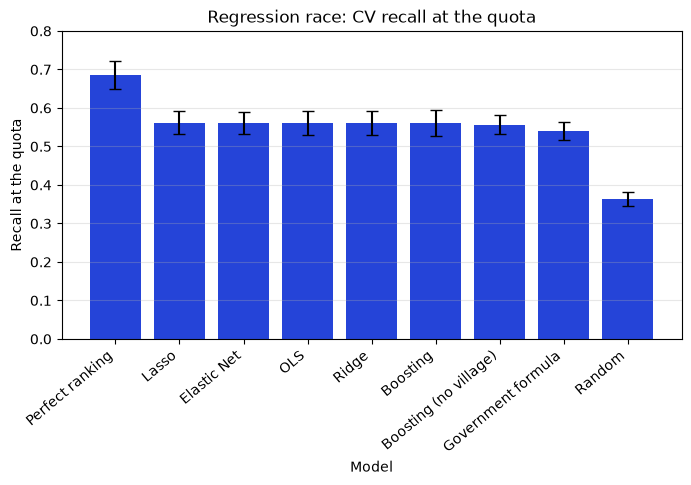

In [33]:
# Plot
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(final.index, final["recall mean"], yerr=final["recall std"],  
       capsize=4, color="#2544d8")   # bar color

# Aesthetics
ax.set_ylim(0, 0.8)   
ax.set_xlabel("Model")
ax.set_ylabel("Recall at the quota")
ax.set_title("Regression race: CV recall at the quota")
ax.grid(axis="y", alpha=0.3)
ax.set_xticks(range(len(final)))   # one tick per bar
ax.set_xticklabels(final.index, rotation=40, ha="right") 
fig.savefig("../outputs/figures/04a_regression_setA_figure4.png", dpi=200, bbox_inches="tight")   # saved for the report
plt.show()

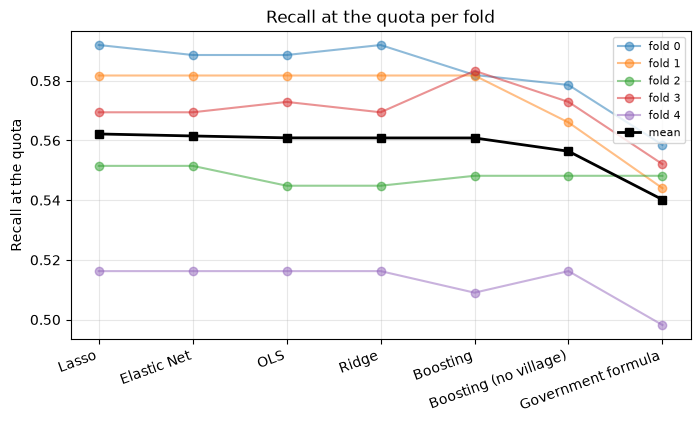

In [31]:
# Plot 2: recall in every fold (one line per fold)
plot_models = [m for m in final.index if m not in ["Random", "Perfect ranking"]]
recall_by_fold = fold_results_boost.pivot(index="fold", columns="model", values="recall")[plot_models]

fig, ax = plt.subplots(figsize=(8, 4))
for k in recall_by_fold.index:                                    
    ax.plot(recall_by_fold.columns, recall_by_fold.loc[k], marker="o", alpha=0.5, label=f"fold {k}")
ax.plot(plot_models, final.loc[plot_models, "recall mean"], color="black", marker="s", linewidth=2, label="mean") 

# Aesthetics
ax.set_ylabel("Recall at the quota")
ax.set_title("Recall at the quota per fold")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
ax.set_xticks(range(len(plot_models)))   # one tick per model
ax.set_xticklabels(plot_models, rotation=20, ha="right")   # turn the labels, right end under each model
fig.savefig("../outputs/figures/04a_regression_setA_figure5.png", dpi=200, bbox_inches="tight")   # saved for the report
plt.show()

In [32]:
# Paired check: compare the models fold by fold (same villages in every fold)
by_fold = fold_results_boost.pivot(index="fold", columns="model", values="recall")   # one row per fold
paired = pd.DataFrame({
    "OLS - Government formula": by_fold["OLS"] - by_fold["Government formula"],  # gain over the government in each fold
    "Boosting - OLS": by_fold["Boosting"] - by_fold["OLS"],  # does boosting beat OLS in the same villages?
})
display(paired.round(3))
for col in paired.columns:
    print(f"{col}: mean {paired[col].mean():.3f} | std {paired[col].std():.3f} | folds above 0: {(paired[col] > 0).sum()} of 5")

,OLS - Government formula,Boosting - OLS
fold,,
0,0.030,-0.007
1,0.038,0.000
2,-0.003,0.003
3,0.021,0.010
4,0.018,-0.007


OLS - Government formula: mean 0.021 | std 0.016 | folds above 0: 4 of 5
Boosting - OLS: mean -0.000 | std 0.007 | folds above 0: 2 of 5


**Result:**

All six models reach almost the same recall at the quota, between 55.6% and 56.2%. The differences are much smaller than the spread between the folds, so no model is really better than the others. The paired check confirms this: fold by fold, boosting minus OLS is about 0 (between -0.7 and +1.0 points).

With the simplicity rule, OLS is the winner of the regression race. With the stricter rule (one standard error instead of one standard deviation), OLS also wins.

OLS beats the government formula in 4 of the 5 folds, by 2.1 points on average (std 1.6). This gain is small but fairly consistent. The final test has to confirm it in new villages.

Between a random ranking (36.4%) and a perfect ranking (68.6%), OLS reaches 61% of the possible improvement. The government formula reaches 55%.

### 11. Conclusion

In this notebook we predicted log consumption with five models: OLS, Ridge, Lasso, Elastic Net and boosting. We used the same village folds for all models. All filling and scaling happened inside the pipeline, so it was learned only from the training folds. The test villages were not used.

With the MSE, the four linear models are tied (about 0.234). The penalty does not help, because we have many households per feature, and the features from the government formula were already chosen to be useful. Boosting has a lower MSE (0.222), but mostly because it uses the village-level columns.

With recall at the quota, all models find about 56 out of 100 poor households. The within-village AUC shows why boosting does not find more: the village-level columns help to compare villages, but not households in the same village.

With the simplicity rule, OLS is the winner. Our OLS is a simplified version of the government's method: one formula for all areas instead of one per district and urban/rural area. It finds about 2 more poor households out of 100 than the government formula (2.1 points on average, better in 4 of the 5 folds). This is about the same as the government refit in our baselines (56.4%). So the gain comes from estimating the formula again on this data, not from a better method. The gain is small but fairly consistent, and the final test has to show if it holds in new villages.

Whether predicting consumption is better than predicting poverty directly (04b) is compared in 05_evaluation, together with the final test.